# 16. GTX-A 유사사례 공간분석 및 GTX-C 적용 준비

**질문: GTX-C의 개통 전 특성과 비슷한 GTX-A 격자에서는 어떤 승차 변화가 관찰됐는가?**

이 노트북은 개통 후 승차인원 확정 예측이나 인과효과 추정이 아니라 **비교 사례와 적용 한계를 제시하는 탐색적 분석**이다. 기존 KNN의 최근접 사례 탐색과 같은 원리를 쓰므로 예측 한계를 해결한 새 기법이라고 주장하지 않는다.

1. 기존 GTX-A 250m 126개 격자 자료 확인
2. 개통 전 변수만으로 다른 역의 유사 사례 5개 찾기
3. 실제 변화의 일치 정도를 개통 전 승차규모만 이용한 사례 탐색과 비교
4. 권역별 사례표·그림 및 자료 범위 점검
5. GTX-C 입력자료 준비 상태와 적용 함수

결과 CSV·이미지·모델 파일 자동 저장은 없다. 노트북 출력에서 확인한다. 기존 분석 파일은 수정하지 않는다.

In [1]:
# 프로젝트 루트(UROP) 자동 탐색 — 절대경로 없이 어느 컴퓨터에서도 동작
import sys
from pathlib import Path
UROP_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.py').is_file() and (p / 'code').is_dir())
for _d in [UROP_ROOT, *sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir() and d.name != '__pycache__')]:
    if str(_d) not in sys.path:
        sys.path.append(str(_d))

from pathlib import Path
import sys, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
paths=[*sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir()), Path.cwd(), Path.cwd()/'analysis', Path.cwd()/'gtx_a_bus_analysis'/'analysis', Path.cwd()/'github_2026-UROP'/'gtx_a_bus_analysis'/'analysis']
ANALYSIS=next((p for p in paths if (p/'analog_case_analysis.py').exists()),None)
if ANALYSIS is None: raise FileNotFoundError('프로젝트 또는 analysis 폴더에서 실행하세요.')
if str(ANALYSIS) not in sys.path: sys.path.insert(0,str(ANALYSIS))
import ridge_count_validation as source
import analog_case_analysis as analog
importlib.reload(analog)
fonts={f.name for f in font_manager.fontManager.ttflist}
font=next((f for f in ['AppleGothic','Apple SD Gothic Neo','NanumGothic','Malgun Gothic','Noto Sans CJK KR'] if f in fonts),None)
if font: plt.rcParams['font.family']=font
plt.rcParams.update({'axes.unicode_minus':False,'figure.dpi':110,'font.size':11})
pd.set_option('display.max_columns',30)
data=source.load_data().sort_values('셀 ID').reset_index(drop=True)
data['change']=data.board_2025_all-data.board_2024_all
data['rate']=100*data.change/data.board_2024_all.where(data.board_2024_all>0)
assert len(data)==126 and data['셀 ID'].is_unique
analog.features(data,analog.FEATURES)
display(data.groupby('nearest_station').agg(격자수=('셀 ID','size'),개통전승차=('board_2024_all','sum'),개통후승차=('board_2025_all','sum'),감소격자=('change',lambda s:(s<0).sum())))
display(pd.DataFrame({'입력열':analog.FEATURES,'정의':analog.LABELS,'결측수':data[analog.FEATURES].isna().sum().to_numpy()}))

,격자수,개통전승차,개통후승차,감소격자
nearest_station,,,,
대곡,37,2622.0,1016.0,34
운정중앙,63,6491.0,1911.0,58
킨텍스,26,8781.0,2658.0,25


,입력열,정의,결측수
0,board_2024_all,개통 전 승차인원(명),0
1,log1p_walk_min,log(1+보행시간[분]),0
2,competing_share,경쟁 목적지 비율(%),0
3,bus_time_mean,버스 평균 통행시간(분),0
4,log1p_floor_area,log(1+연면적[천㎡]),0


## 1. 비교 규칙을 먼저 고정

- 기존 5변수 구성 유지: 개통 전 승차인원(원 단위), log(1+보행시간), 경쟁 목적지 비율, 버스 통행시간, log(1+연면적[천㎡]). **수요 비중 제외**.
- 고정 K=5. 결과를 본 뒤 변수나 K를 최적화하지 않는다. 5는 사례표를 읽기 위한 운영상 선택이며 최적값이라는 주장은 하지 않는다.
- 남겨 둔 역은 사례 후보와 표준화 기준에서 완전히 제외. 참조 자료의 평균·표준편차로 표준화한 뒤 동일 가중 유클리드 거리 사용.
- 거리 계산에 2025년 승차량·변화량·변화율을 넣지 않는다. 최근접 순서는 **수요 전망 순위가 아니라 특성의 유사도 순서**다.
- 결측 비교 변수는 조용히 대체하지 않고 오류로 알린다. 참조자료에서 값이 일정한 변수·범위를 벗어난 대상도 별도 확인한다.
- 개통 전 승차인원만 사용한 최근접 5개와 비교해 지역정보의 추가 도움이 있는지 진단한다.
- 가까운 후보 5개를 찾았다고 충분히 비슷하다는 뜻은 아니다. 참조역 간 5개 평균거리의 95분위 초과를 경고로 표시한다. 이는 **통계적 신뢰수준이나 적용 승인 기준이 아니다**.
- 작은 기초 승차량의 변화율은 불안정하므로 원 단위 변화와 기초 승차량을 함께 제시한다. 0명인 경우 변화율은 계산하지 않는다. 20명 미만 표시는 설명용이며 제외하지 않는다.

In [2]:
summary, cases=analog.validate(data)
report=(summary.groupby(['방식','권역'],sort=False)
 .agg(격자수=('셀 ID','size'),사례중앙값과실제차이_MAE=('중앙값차이절대값','mean'),
      실제가사례최소최대사이인비율=('사례범위내','mean'),사례변화범위_IQR중앙값=('사례변화IQR','median'),
      평균거리중앙값=('평균거리','median'),먼사례주의수=('먼사례주의','sum')))
display(report.round(3))
overall=summary.groupby('방식').agg(격자수=('셀 ID','size'),사례중앙값과실제차이_MAE=('중앙값차이절대값','mean'),사례범위내비율=('사례범위내','mean'))
display(overall.round(3))
main=summary[summary['방식']=='지역교통5변수'].copy()
print('범위 밖 변수가 있는 격자:',main['범위밖변수'].ne('').sum())
display(main.loc[main['먼사례주의']|main['범위밖변수'].ne(''),['셀 ID','권역','평균거리','거리경고선','먼사례주의','범위밖변수']].round(3))

범위 밖 변수가 있는 격자: 10


,,격자수,사례중앙값과실제차이_MAE,실제가사례최소최대사이인비율,사례변화범위_IQR중앙값,평균거리중앙값,먼사례주의수
방식,권역,,,,,,
지역교통5변수,운정중앙,63,44.175,0.635,29.0,0.555,0
승차규모만,운정중앙,63,14.651,0.746,4.0,0.011,0
지역교통5변수,킨텍스,26,119.269,0.500,26.5,0.496,5
승차규모만,킨텍스,26,104.962,0.654,12.0,0.033,6
지역교통5변수,대곡,37,25.892,0.676,36.0,0.386,2
승차규모만,대곡,37,7.027,0.811,5.0,0.008,0


,격자수,사례중앙값과실제차이_MAE,사례범위내비율
방식,,,
승차규모만,126,31.048,0.746
지역교통5변수,126,54.302,0.619


,셀 ID,권역,평균거리,거리경고선,먼사례주의,범위밖변수
6,1118,운정중앙,0.419,1.724,False,log1p_floor_area
12,4012,운정중앙,1.036,1.724,False,log1p_walk_min
34,9893,운정중앙,0.924,1.724,False,log1p_walk_min
36,10111,운정중앙,0.893,1.724,False,log1p_walk_min
50,12580,운정중앙,1.332,1.724,False,bus_time_mean
133,4934,킨텍스,4.035,1.284,True,board_2024_all
137,8868,킨텍스,1.885,1.284,True,log1p_walk_min
141,10274,킨텍스,1.688,1.284,True,
146,12765,킨텍스,1.636,1.284,True,log1p_walk_min
148,13793,킨텍스,1.302,1.284,True,


## 2. 같은 특성의 사례에서 변화도 비슷했는가?

아래 MAE는 **사례들의 변화량 중앙값과 대상 실제 변화량 사이의 차이**를 진단하는 값이다. 앞의 Ridge 승차인원 예측 MAE와 추정 절차가 다르다. 두 유사사례 방식끼리 비교한다. 같은 자료로 방법을 여러 번 검토한 탐색이라는 한계가 남는다.

사례 최소~최대 사이에 실제값이 들어가는 비율은 예측구간의 보장된 포함률이 아니다. 사례 범위가 넓으면 쉽게 높아질 수 있으므로 IQR과 함께 확인한다. 단순 감소/비감소 일치율은 117개 감소라는 불균형 때문에 주 검증지표로 사용하지 않는다.

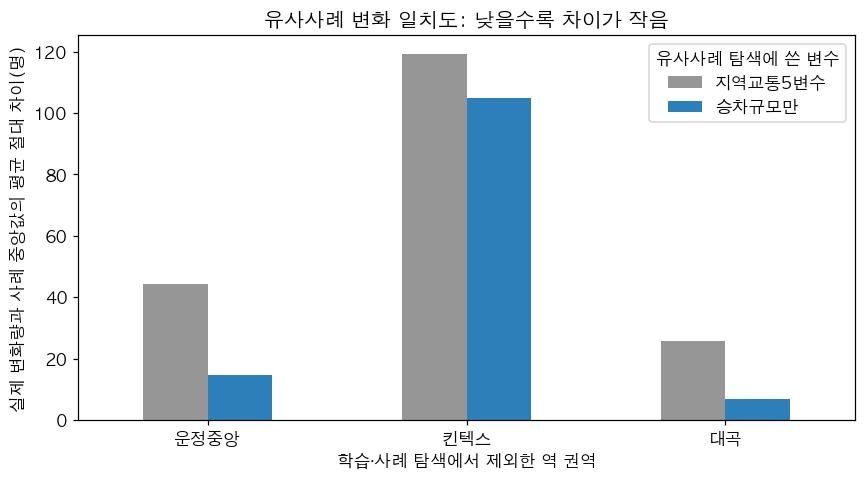

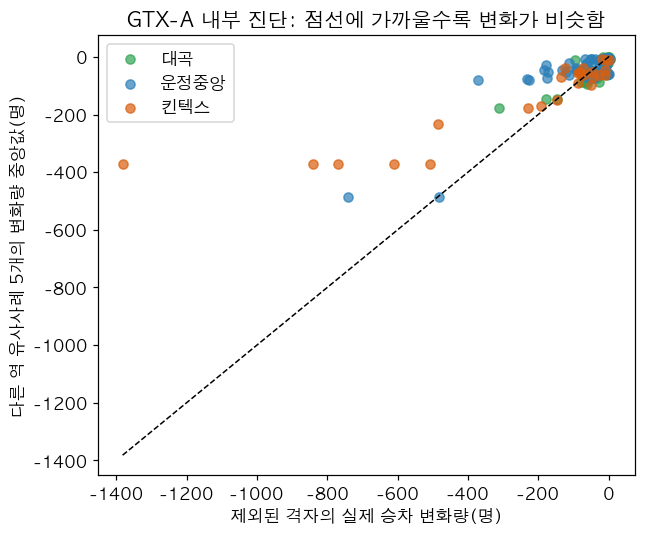

In [3]:
fig,ax=plt.subplots(figsize=(8,4.5))
report['사례중앙값과실제차이_MAE'].unstack(0).reindex(['운정중앙','킨텍스','대곡']).plot.bar(ax=ax,color=['#969696','#2C7FB8'])
ax.set_xlabel('학습·사례 탐색에서 제외한 역 권역')
ax.set_ylabel('실제 변화량과 사례 중앙값의 평균 절대 차이(명)')
ax.set_title('유사사례 변화 일치도: 낮을수록 차이가 작음')
ax.tick_params(axis='x',rotation=0); ax.legend(title='유사사례 탐색에 쓴 변수')
plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(6,5))
colors={'운정중앙':'#2C7FB8','킨텍스':'#D95F0E','대곡':'#31A354'}
for station,g in main.groupby('권역'):
 ax.scatter(g['실제변화량'],g['사례변화중앙값'],label=station,color=colors[station],alpha=.7)
bounds=[min(main['실제변화량'].min(),main['사례변화중앙값'].min()),max(main['실제변화량'].max(),main['사례변화중앙값'].max())]
ax.plot(bounds,bounds,'k--',lw=1)
ax.set_xlabel('제외된 격자의 실제 승차 변화량(명)')
ax.set_ylabel('다른 역 유사사례 5개의 변화량 중앙값(명)')
ax.set_title('GTX-A 내부 진단: 점선에 가까울수록 변화가 비슷함')
ax.legend(); plt.tight_layout(); plt.show()

## 3. 권역별 실제 사례 카드

권역마다 **평균 유사거리 순서의 중간에 있는 대상 격자**를 자동 표시한다. 결과가 잘 맞는 격자를 고르지 않는다. `SELECTED_IDS`에 관심 셀 ID를 넣어 바꿀 수 있다. 정류장명·시설명·인과적 설명은 이 표만으로 추정하지 않는다.

검은 점은 대상 실제 변화, 파란 선·점은 다섯 비교사례의 관찰 범위와 중앙값이다. 이것은 GTX-C의 예측구간이 아니다.


운정중앙 대상 셀 5703: 실제 변화 -67명 / 거리주의 False

킨텍스 대상 셀 4205: 실제 변화 -10명 / 거리주의 False

대곡 대상 셀 3658: 실제 변화 -21명 / 거리주의 False


,셀 ID,nearest_station,board_2024_all,board_2025_all,log1p_walk_min,competing_share,bus_time_mean,log1p_floor_area
39,5703,운정중앙,95.0,28.0,4.958,0.0,39.377,0.401


,유사순서,사례셀,사례권역,거리,개통전승차,개통후승차,변화량,변화율(%),log1p_walk_min,competing_share,bus_time_mean,log1p_floor_area
85,1,7608,대곡,0.300,11.0,6.0,-5.0,-45.455,5.133,9.091,40.283,0.531
86,2,14004,대곡,0.339,1.0,4.0,3.0,300.000,4.794,0.000,33.917,0.184
87,3,3658,대곡,0.703,35.0,14.0,-21.0,-60.000,4.151,0.000,44.856,0.808
88,4,4131,대곡,0.711,19.0,11.0,-8.0,-42.105,4.029,0.000,41.334,0.458
89,5,2268,킨텍스,0.724,9.0,3.0,-6.0,-66.667,4.105,0.000,37.139,0.941


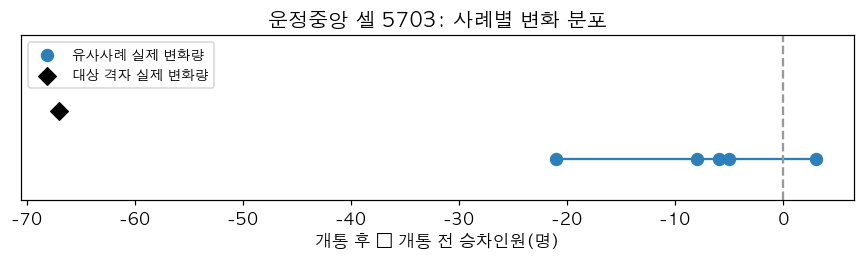

,셀 ID,nearest_station,board_2024_all,board_2025_all,log1p_walk_min,competing_share,bus_time_mean,log1p_floor_area
31,4205,킨텍스,11.0,1.0,3.879,0.0,48.814,2.736


,유사순서,사례셀,사례권역,거리,개통전승차,개통후승차,변화량,변화율(%),log1p_walk_min,competing_share,bus_time_mean,log1p_floor_area
345,1,10336,운정중앙,0.396,63.0,22.0,-41.0,-65.079,4.212,0.000,44.652,2.328
346,2,15474,운정중앙,0.495,69.0,43.0,-26.0,-37.681,4.177,0.000,51.651,2.003
347,3,12856,운정중앙,0.496,125.0,34.0,-91.0,-72.800,3.697,0.000,45.159,2.180
348,4,2716,대곡,0.554,73.0,29.0,-44.0,-60.274,3.595,15.068,41.393,2.512
349,5,2586,운정중앙,0.557,96.0,32.0,-64.0,-66.667,3.764,0.000,38.454,2.497


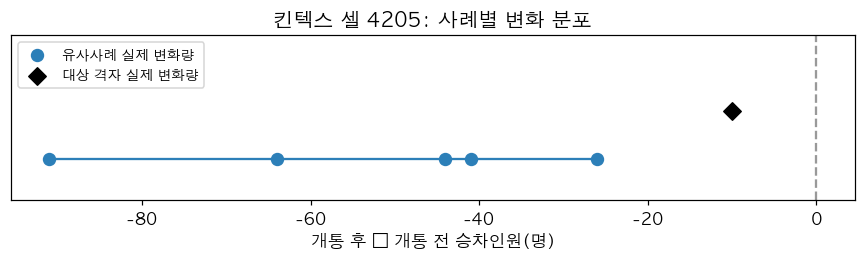

,셀 ID,nearest_station,board_2024_all,board_2025_all,log1p_walk_min,competing_share,bus_time_mean,log1p_floor_area
27,3658,대곡,35.0,14.0,4.151,0.0,44.856,0.808


,유사순서,사례셀,사례권역,거리,개통전승차,개통후승차,변화량,변화율(%),log1p_walk_min,competing_share,bus_time_mean,log1p_floor_area
495,1,14062,킨텍스,0.344,21.0,23.0,2.0,9.524,3.667,0.0,41.466,0.772
496,2,1278,킨텍스,0.359,132.0,51.0,-81.0,-61.364,3.613,0.0,46.123,0.636
497,3,7433,운정중앙,0.404,18.0,7.0,-11.0,-61.111,4.108,0.0,38.638,0.520
498,4,1572,운정중앙,0.409,73.0,24.0,-49.0,-67.123,4.718,0.0,43.979,0.375
499,5,559,운정중앙,0.412,82.0,31.0,-51.0,-62.195,3.936,0.0,40.055,0.333


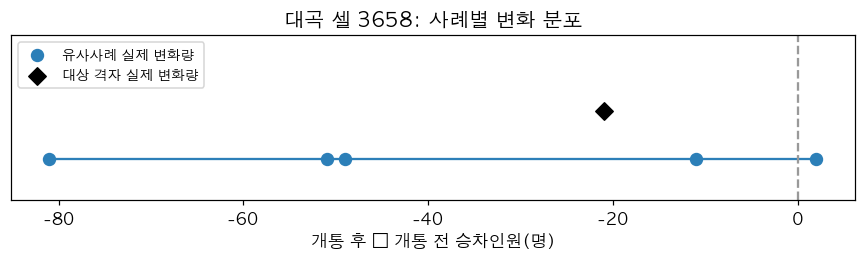

In [4]:
SELECTED_IDS=[int(g.sort_values(['평균거리','셀 ID']).iloc[len(g)//2]['셀 ID']) for _,g in main.groupby('권역',sort=False)]
for cell_id in SELECTED_IDS:
 target=main[main['셀 ID']==cell_id].iloc[0]
 sub=cases[cases['대상셀']==cell_id].copy()
 print(f"\n{target['권역']} 대상 셀 {cell_id}: 실제 변화 {target['실제변화량']:.0f}명 / 거리주의 {target['먼사례주의']}")
 display(data.loc[data['셀 ID']==cell_id,['셀 ID','nearest_station','board_2024_all','board_2025_all',*analog.FEATURES[1:]]].round(3))
 display(sub[['유사순서','사례셀','사례권역','거리','개통전승차','개통후승차','변화량','변화율(%)',*analog.FEATURES[1:]]].round(3))
 fig,ax=plt.subplots(figsize=(8,2.5))
 ax.scatter(sub['변화량'],np.zeros(len(sub)),s=60,color='#2C7FB8',label='유사사례 실제 변화량')
 ax.hlines(0,sub['변화량'].min(),sub['변화량'].max(),color='#2C7FB8')
 ax.scatter([target['실제변화량']],[.35],color='black',marker='D',s=65,label='대상 격자 실제 변화량')
 ax.axvline(0,color='#999999',ls='--'); ax.set_yticks([]); ax.set_ylim(-.3,.9)
 ax.set_xlabel('개통 후 − 개통 전 승차인원(명)'); ax.set_title(f"{target['권역']} 셀 {cell_id}: 사례별 변화 분포")
 ax.legend(loc='upper left',fontsize=9); plt.tight_layout(); plt.show()

## 4. GTX-C 적용 준비

현재 프로젝트의 `gtx_bc_bus_collection/processed`에는 좌표가 붙은 OD 파일이 있지만, 이 노트북에 필요한 C 격자 통합 특성표는 확인되지 않았다. **OD 행을 격자로 간주하거나 미구축 값을 0으로 채우지 않는다.**

| 공통 입력 | C에서 확인할 내용 |
|---|---|
| 셀 ID·역 권역 | 250m 격자, 의정부·덕정 배정 기준. A와 비교 가능한 포함 범위 확인 |
| 개통 전 승차인원 | C 기준연도 명시, 종일·서울행·노선 선정 기준 일치. C는 개통 후 자료가 없어 공급유지 조건을 그대로 적용할 수 없다는 차이 명시 |
| 보행시간 | 동일 출발점·GTX역 접근점·분 단위, log(1+분) |
| 경쟁 목적지 비율 | A의 연신내·서울역 기준을 C에 복사하지 않음. 노선별 GTX 도달 목적지에 대한 공통 정의를 마련하고 필요하면 A도 재구축 |
| 버스 통행시간 | 동일 유효시간 규칙·OD 가중치·분 단위 |
| 건축물 연면적 | 같은 공간집계와 천㎡ 단위, log(1+천㎡) |

`board_2024_all`은 기존 코드 호환용 열 이름이다. C의 2025년 개통 전 승차량을 사용한다면 이 열에 매핑하되 기준연도를 별도 기록한다. C의 실제 개통 후 값은 필요하지 않다. 미래 개통 시점까지 개발·노선변경이 생길 수 있다는 한계도 기록한다.

In [5]:
C_ROOT=UROP_ROOT/'data'/'processed'/'gtx_bc'
files=sorted(C_ROOT.rglob('*with_coordinates.csv'))
print('현재 확인된 C 좌표 매칭 OD 파일:')
for path in files: print(path.relative_to(C_ROOT))
print('아래 C 입력표를 채우고 정의를 확인한 뒤에만 사례 탐색을 실행합니다.')
c_frame=pd.DataFrame(columns=['셀 ID','nearest_station',*analog.FEATURES])
C_DEFINITION_CONFIRMED=False
if c_frame.empty:
 print('C 격자별 5변수 통합자료 미입력: C 비교 결과는 아직 생성하지 않았습니다.')
else:
 c_summary,c_cases=analog.apply_c(data,c_frame,definition_confirmed=C_DEFINITION_CONFIRMED)
 display(c_summary.round(3))
 display(c_cases.round(3))

현재 확인된 C 좌표 매칭 OD 파일:
transport_card/gtx_c_transport_card_20241017_seoul_od_with_coordinates.csv
transport_card/gtx_c_transport_card_20251106_seoul_od_with_coordinates.csv
아래 C 입력표를 채우고 정의를 확인한 뒤에만 사례 탐색을 실행합니다.
C 격자별 5변수 통합자료 미입력: C 비교 결과는 아직 생성하지 않았습니다.


## 5. 보고서 해석 기준

- 5변수 사례가 승차규모만 비교한 사례보다 실제 변화와 더 일치하는지 역별로 확인한다. 우위가 없으면 유사사례 결과를 C 미래 수요 전망의 근거로 확대하지 않는다.
- C의 결과는 “현재 구축한 특성이 유사한 A의 사례”이다. 그 사례들의 변화 평균이나 중앙값을 C의 예상 감소율로 제시하지 않는다.
- 거리 경고·범위 밖 변수·참조사례가 한 역에 집중되는 경우를 함께 표시한다. 경고가 없다고 전이가 입증되는 것은 아니다.
- 원래 승차량이 적은 격자의 변화율, 한 날짜의 합성자료, 3개 역의 한계가 그대로 남는다.
- OLS의 관련성 결과·현장관찰과 함께 해석하되, 사례 비교만으로 GTX 수단전환이나 버스 공급 축소 필요성을 확정하지 않는다.
- 현재 완료 범위: **A의 역 간 유사사례 비교·검증**. C 적용은 공통 특성표와 변수 정의 검토 후 진행한다.

## 이번 실행 결과와 판단 (2026-10-17)

| 사례 탐색 방식 | 실제 변화량과 사례 변화량 중앙값 간 평균 절대 차이 | 실제 변화가 사례 최소~최대 사이인 비율 |
|---|---:|---:|
| 개통 전 승차규모만 | 31.05명 | 74.6% |
| 지역·교통 5변수 | 54.30명 | 61.9% |

5변수 방식의 차이는 운정중앙 44.17명, 킨텍스 119.27명, 대곡 25.89명으로, 세 권역 모두 승차규모만 이용한 방식보다 컸다. 거리 경고 격자는 7개였다. 경고선은 진단용이며, 나머지 격자의 비교 타당성이 보장되는 것은 아니다.

**이번 구성으로는 특성이 유사한 A 격자들이 수요 변화도 유사하다고 뒷받침되지 않았다.** 따라서 GTX-C 적용은 특성과 사례를 대조하는 탐색적 공간 사례분석 범위로 한정하며, 사례 변화량을 C의 예상 변화량으로 옮기지 않는다. 승차규모가 다른 사례끼리 절대 변화량을 비교하는 한계도 사례표에서 함께 확인한다. 표준화만으로 규모 차이가 제거되는 것은 아니다.

이 결과를 보고 거리 가중치·K·변수를 계속 조정해 외부역 점수를 높이는 작업은 하지 않았다. C 격자 통합 특성표가 없으므로 실제 C 사례표는 아직 생성하지 않았다.